# 07 — Calibrate and evaluate the waveform model

Validation subjects are used for probability calibration and threshold selection.
The frozen policy is then evaluated once on held-out test subjects. Report accuracy
together with balanced accuracy, good-class F1, sensitivity, specificity, ROC-AUC,
and false-acceptance rate; accuracy alone is misleading for this imbalanced dataset.

In [1]:
from pathlib import Path
import os
import sys


def find_repository_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "apps").exists():
            return candidate
    raise RuntimeError("Run this notebook from inside the pure-pulsesure repository")


REPO_ROOT = find_repository_root(Path.cwd().resolve())
AI_SERVICE_ROOT = REPO_ROOT / "apps" / "ai-service"
sys.path.insert(0, str(AI_SERVICE_ROOT))

RAW_DIR = Path(
    os.environ.get("PURE_BUT_PPG_DIR", REPO_ROOT / "data" / "raw" / "but-ppg-2.0.0")
).expanduser().resolve()
WAVEFORM_DIR = Path(
    os.environ.get("PURE_WAVEFORM_DIR", REPO_ROOT / "data" / "processed" / "but-ppg-waveforms-v2")
).expanduser().resolve()
MODEL_DIR = Path(os.environ.get("PURE_MODEL_DIR", REPO_ROOT / "models")).expanduser().resolve()

print("Repository:", REPO_ROOT)
print("Raw dataset:", RAW_DIR)
print("Waveform dataset:", WAVEFORM_DIR)
print("Model directory:", MODEL_DIR)

Repository: /mnt/home/gracewahyuni06/pure-pulsesure
Raw dataset: /mnt/home/gracewahyuni06/pure-pulsesure/data/raw/but-ppg-2.0.0
Waveform dataset: /mnt/home/gracewahyuni06/pure-pulsesure/data/processed/but-ppg-waveforms-v2
Model directory: /mnt/home/gracewahyuni06/pure-pulsesure/models


In [2]:
import json
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch.utils.data import DataLoader, TensorDataset

from app.models.waveform_resnet import PPGQualityResNet1D

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
archive = np.load(WAVEFORM_DIR / "waveforms.npz")
X = archive["X"].astype(np.float32)
y = archive["y"].astype(int)
split = archive["split"].astype(str)
record_ids = archive["record_id"].astype(str)

checkpoint_path = MODEL_DIR / "candidates" / "waveform_resnet1d.pt"
model = PPGQualityResNet1D().to(DEVICE)
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
model.eval()

PPGQualityResNet1D(
  (encoder): Sequential(
    (0): Conv1d(3, 32, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ResidualBlock1D(
      (main): Sequential(
        (0): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
        (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): SqueezeExcitation1D(
          (pool): AdaptiveAvgPool1d(output_size=1)
          (gate): Sequential(
            (0): Conv1d(32, 4, kernel_size=(1,), stride=(1,))
            (1): ReLU(inplace=True)
            (2): Conv1d(4, 32, kernel_size=(1,), stride=(1,))
         

In [3]:
def infer(indices):
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X[indices]), torch.from_numpy(y[indices])),
        batch_size=128,
        shuffle=False,
    )
    logits, labels = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            logits.append(model(inputs.to(DEVICE)).cpu().numpy())
            labels.append(targets.numpy())
    return np.concatenate(labels).astype(int), np.concatenate(logits)

validation_indices = np.flatnonzero(split == "validation")
test_indices = np.flatnonzero(split == "test")
y_validation, logits_validation = infer(validation_indices)
y_test, logits_test = infer(test_indices)

# Platt calibration is fitted only on validation subjects.
calibrator = LogisticRegression(C=1e3, solver="lbfgs", random_state=2026)
calibrator.fit(logits_validation.reshape(-1, 1), y_validation)
probability_validation = calibrator.predict_proba(logits_validation.reshape(-1, 1))[:, 1]
probability_test = calibrator.predict_proba(logits_test.reshape(-1, 1))[:, 1]

In [4]:
def binary_metrics(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    return {
        "threshold": float(threshold),
        "accuracy": float(np.mean(predictions == labels)),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "precision_good": precision_score(labels, predictions, zero_division=0),
        "recall_good_sensitivity": recall_score(labels, predictions, zero_division=0),
        "specificity_poor": float(tn / max(tn + fp, 1)),
        "f1_good": f1_score(labels, predictions, zero_division=0),
        "false_acceptance_rate": float(fp / max(tn + fp, 1)),
        "false_rejection_rate": float(fn / max(fn + tp, 1)),
        "roc_auc": roc_auc_score(labels, probabilities),
        "average_precision": average_precision_score(labels, probabilities),
        "confusion_matrix": matrix.tolist(),
    }

candidates = [binary_metrics(y_validation, probability_validation, threshold) for threshold in np.linspace(0.02, 0.98, 193)]
safe_candidates = [item for item in candidates if item["false_acceptance_rate"] <= 0.10]
selection_pool = safe_candidates or candidates
validation_choice = max(selection_pool, key=lambda item: (item["balanced_accuracy"], item["f1_good"]))
binary_threshold = validation_choice["threshold"]

test_binary = binary_metrics(y_test, probability_test, binary_threshold)
display(pd.DataFrame([validation_choice, test_binary], index=["validation", "test"]).drop(columns="confusion_matrix"))

,threshold,accuracy,balanced_accuracy,precision_good,recall_good_sensitivity,specificity_poor,f1_good,false_acceptance_rate,false_rejection_rate,roc_auc,average_precision
validation,0.28,0.873684,0.826614,0.634731,0.751773,0.901454,0.688312,0.098546,0.248227,0.863106,0.741121
test,0.28,0.634375,0.685357,0.404192,0.794118,0.576596,0.535714,0.423404,0.205882,0.771552,0.502394


In [5]:
def gate_metrics(labels, probabilities, lower, upper):
    reliable = probabilities >= upper
    unreliable = probabilities <= lower
    caution = ~(reliable | unreliable)
    good = labels == 1
    poor = labels == 0
    return {
        "lower_threshold": float(lower),
        "upper_threshold": float(upper),
        "false_acceptance_rate": float(np.mean(reliable[poor])),
        "false_rejection_rate": float(np.mean(unreliable[good])),
        "good_acceptance_rate": float(np.mean(reliable[good])),
        "poor_rejection_rate": float(np.mean(unreliable[poor])),
        "reliable_coverage": float(np.mean(reliable)),
        "caution_rate": float(np.mean(caution)),
        "unreliable_rate": float(np.mean(unreliable)),
    }

upper_candidates = []
for upper in np.linspace(binary_threshold, 0.99, 150):
    upper_candidates.append(gate_metrics(y_validation, probability_validation, 0.0, upper))
feasible_upper = [item for item in upper_candidates if item["false_acceptance_rate"] <= 0.05]
upper_threshold = max(feasible_upper or upper_candidates, key=lambda item: item["good_acceptance_rate"])["upper_threshold"]

lower_candidates = []
for lower in np.linspace(0.01, min(binary_threshold, upper_threshold - 0.01), 150):
    lower_candidates.append(gate_metrics(y_validation, probability_validation, lower, upper_threshold))
feasible_lower = [item for item in lower_candidates if item["false_rejection_rate"] <= 0.05]
lower_threshold = max(feasible_lower or lower_candidates, key=lambda item: item["poor_rejection_rate"])["lower_threshold"]

validation_gate = gate_metrics(y_validation, probability_validation, lower_threshold, upper_threshold)
test_gate = gate_metrics(y_test, probability_test, lower_threshold, upper_threshold)
display(pd.DataFrame([validation_gate, test_gate], index=["validation", "test"]))

,lower_threshold,upper_threshold,false_acceptance_rate,false_rejection_rate,good_acceptance_rate,poor_rejection_rate,reliable_coverage,caution_rate,unreliable_rate
validation,0.024497,0.384832,0.048465,0.049645,0.666667,0.323102,0.163158,0.564474,0.272368
test,0.024497,0.384832,0.321277,0.017647,0.729412,0.121277,0.429688,0.476562,0.093750


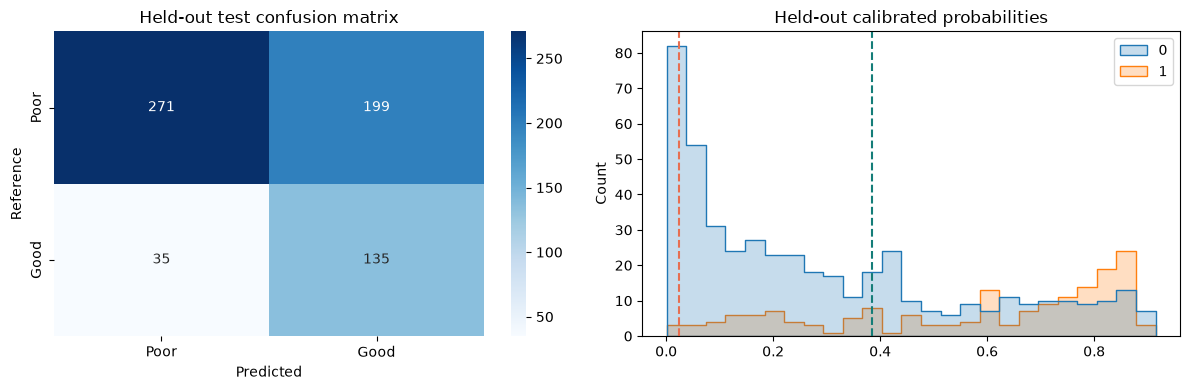

In [6]:
predictions_test = (probability_test >= binary_threshold).astype(int)
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(
    confusion_matrix(y_test, predictions_test, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Poor", "Good"],
    yticklabels=["Poor", "Good"],
    ax=axes[0],
)
axes[0].set_title("Held-out test confusion matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Reference")

sns.histplot(x=probability_test, hue=y_test, bins=25, element="step", ax=axes[1])
axes[1].axvline(lower_threshold, color="#E76F51", linestyle="--")
axes[1].axvline(upper_threshold, color="#147D78", linestyle="--")
axes[1].set_title("Held-out calibrated probabilities")
plt.tight_layout()

In [7]:
production_directory = MODEL_DIR / "production"
production_directory.mkdir(parents=True, exist_ok=True)
production_model = production_directory / "quality_model.pt"
shutil.copy2(checkpoint_path, production_model)

calibration = {
    "method": "platt_logistic_validation_subjects",
    "coefficient": float(calibrator.coef_[0, 0]),
    "intercept": float(calibrator.intercept_[0]),
}
thresholds = {
    "model": "PPGQualityResNet1D",
    "binary_threshold": float(binary_threshold),
    "lower_threshold": float(lower_threshold),
    "upper_threshold": float(upper_threshold),
    "calibration": calibration,
    "quality_score_definition": "round(100 * calibrated_good_quality_probability)",
    "status_policy": {
        "reliable": "probability >= upper_threshold",
        "caution": "lower_threshold < probability < upper_threshold",
        "unreliable": "probability <= lower_threshold",
    },
}
metrics = {
    "validation_binary": validation_choice,
    "test_binary": test_binary,
    "validation_gate": validation_gate,
    "test_gate": test_gate,
    "test_records": int(len(test_indices)),
    "test_subjects": int(np.unique(archive["subject_id"][test_indices]).size),
    "limitations": [
        "BUT PPG is smartphone-camera PPG; MAX30102 deployment requires domain validation.",
        "The dataset label is binary and applies to the full ten-second record.",
        "No target performance is guaranteed before this held-out evaluation runs.",
    ],
}
metadata = {
    "architecture": "PPGQualityResNet1D",
    "input_shape": [3, 300],
    "sampling_rate_hz": 30.0,
    "view_order": ["raw_robust", "butterworth_bandpass", "first_derivative"],
    "channel_policy": "PPG_R matches BUT PPG annotations",
    "model_file": "quality_model.pt",
    "threshold_file": "quality_gate_thresholds.json",
}

(production_directory / "quality_gate_thresholds.json").write_text(json.dumps(thresholds, indent=2) + "\n")
(production_directory / "model_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
(MODEL_DIR / "test_metrics_waveform_v2.json").write_text(json.dumps(metrics, indent=2) + "\n")
print("Production bundle:", production_directory)
print(json.dumps(test_binary, indent=2))

Production bundle: /mnt/home/gracewahyuni06/pure-pulsesure/models/production
{
  "threshold": 0.28,
  "accuracy": 0.634375,
  "balanced_accuracy": 0.6853566958698373,
  "precision_good": 0.4041916167664671,
  "recall_good_sensitivity": 0.7941176470588235,
  "specificity_poor": 0.5765957446808511,
  "f1_good": 0.5357142857142857,
  "false_acceptance_rate": 0.42340425531914894,
  "false_rejection_rate": 0.20588235294117646,
  "roc_auc": 0.7715519399249061,
  "average_precision": 0.502393887444409,
  "confusion_matrix": [
    [
      271,
      199
    ],
    [
      35,
      135
    ]
  ]
}
